# 01 — Dataset Exploration

## Import Libraries

In [42]:

# Import the libraries needed to load the dataset
import pandas as pd
from pathlib import Path


## Load Dataset

In [43]:

# Set the dataset column names
columns = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome"
]

# Locate the dataset in the project folder
project_dir = Path.cwd()

if not (project_dir / "data" / "diabetes.csv").exists():
    project_dir = project_dir.parent

# Load the dataset without a header row
df = pd.read_csv(
    project_dir / "data" / "diabetes.csv",
    header=None,
    names=columns
)

# Preview the first five records
df.head()


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## Dataset Shape

In [44]:

# Check the number of rows and columns
print("Dataset shape:", df.shape)


Dataset shape: (768, 9)


## Dataset Information

In [45]:

# Check column names, data types, and missing values
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


## Statistical Summary

In [46]:

# View the statistical summary of all numerical columns
df.describe()


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


## Target Distribution

In [47]:

# Count the records for each diabetes outcome
df["Outcome"].value_counts()


Outcome
0    500
1    268
Name: count, dtype: int64

## Missing Values

In [48]:

# Count missing values in each column
df.isnull().sum()


Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

## Invalid Zero Values

In [49]:

# Select measurements where zero is not a valid value
invalid_zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

# Count zero values in these columns
zero_counts = (df[invalid_zero_columns] == 0).sum()

# Display the number of invalid zeros
zero_counts


Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

## Duplicate Records

In [50]:

# Count rows that are exact duplicates
duplicate_count = df.duplicated().sum()

# Display the total duplicate records
print("Duplicate records:", duplicate_count)


Duplicate records: 0


## Import Visualization Libraries

In [51]:

# Import libraries for creating charts
import matplotlib.pyplot as plt
import seaborn as sns

# Set a clean style for our visualizations
sns.set_theme(style="whitegrid")


## Diabetes Outcome Distribution

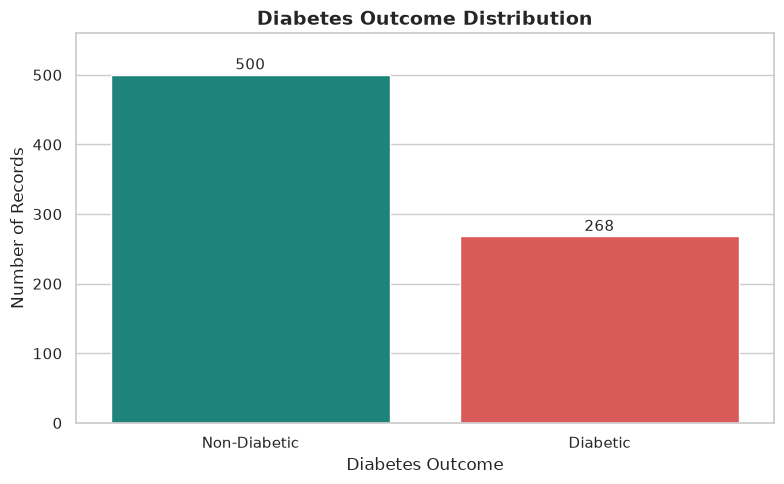

In [52]:

# Count the number of records in each outcome class
outcome_counts = df["Outcome"].value_counts().sort_index()

# Create the outcome distribution chart
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=["Non-Diabetic", "Diabetic"],
    y=outcome_counts.values,
    hue=["Non-Diabetic", "Diabetic"],
    palette=["#0D9488", "#EF4444"],
    legend=False
)

# Display the number of records above each bar
for i, count in enumerate(outcome_counts.values):
    ax.text(i, count + 8, str(count), ha="center", fontsize=11)

# Add chart labels and title
plt.title("Diabetes Outcome Distribution", fontsize=14, fontweight="bold")
plt.xlabel("Diabetes Outcome")
plt.ylabel("Number of Records")
plt.ylim(0, 560)

# Display the chart
plt.tight_layout()
plt.show()


## Feature Distributions

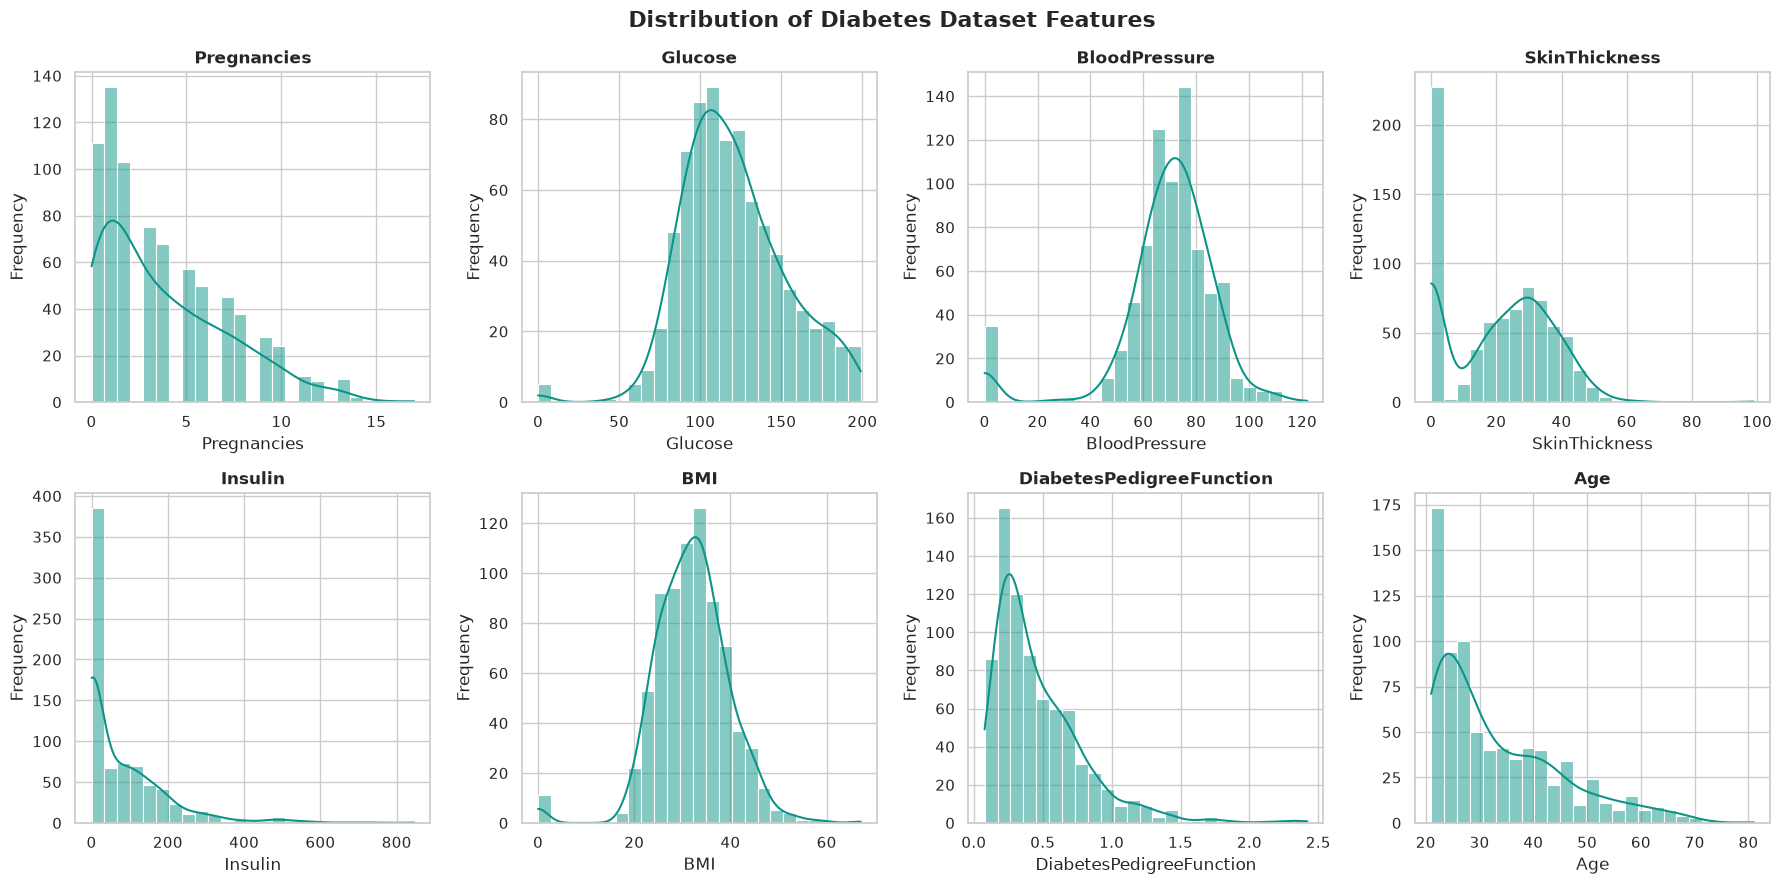

In [53]:

# Select the eight input features
features = df.drop(columns=["Outcome"]).columns

# Create a grid of histograms
fig, axes = plt.subplots(2, 4, figsize=(18, 9))

# Plot the distribution of each feature
for ax, feature in zip(axes.flat, features):
    sns.histplot(
        data=df,
        x=feature,
        bins=25,
        kde=True,
        color="#0D9488",
        ax=ax
    )

    # Add a title and labels to each chart
    ax.set_title(feature, fontsize=12, fontweight="bold")
    ax.set_xlabel(feature)
    ax.set_ylabel("Frequency")

# Add a main title and adjust spacing
fig.suptitle("Distribution of Diabetes Dataset Features", fontsize=16, fontweight="bold")
plt.tight_layout()

# Display all eight histograms
plt.show()


## Feature Comparison by Diabetes Outcome

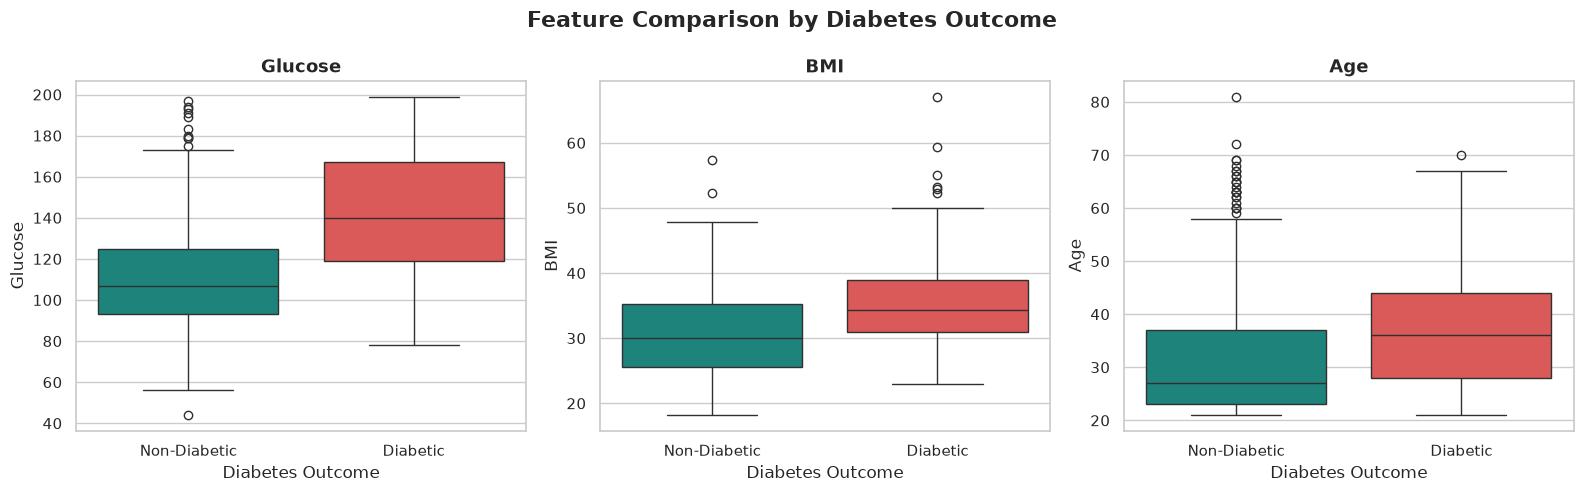

In [54]:

# Select the features we want to compare
selected_features = ["Glucose", "BMI", "Age"]

# Create a copy so the original dataset stays unchanged
eda_df = df.copy()

# Replace invalid zeros in the selected measurements
eda_df[["Glucose", "BMI"]] = eda_df[["Glucose", "BMI"]].replace(0, float("nan"))

# Create three boxplots side by side
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Compare each feature across the two outcome groups
for ax, feature in zip(axes, selected_features):
    sns.boxplot(
        data=eda_df,
        x="Outcome",
        y=feature,
        hue="Outcome",
        palette=["#0D9488", "#EF4444"],
        legend=False,
        ax=ax
    )

    # Add readable labels to each plot
    ax.set_title(feature, fontsize=13, fontweight="bold")
    ax.set_xlabel("Diabetes Outcome")
    ax.set_ylabel(feature)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Non-Diabetic", "Diabetic"])

# Add the main title and adjust spacing
fig.suptitle("Feature Comparison by Diabetes Outcome", fontsize=16, fontweight="bold")
plt.tight_layout()

# Display the boxplots
plt.show()


## Outlier Detection

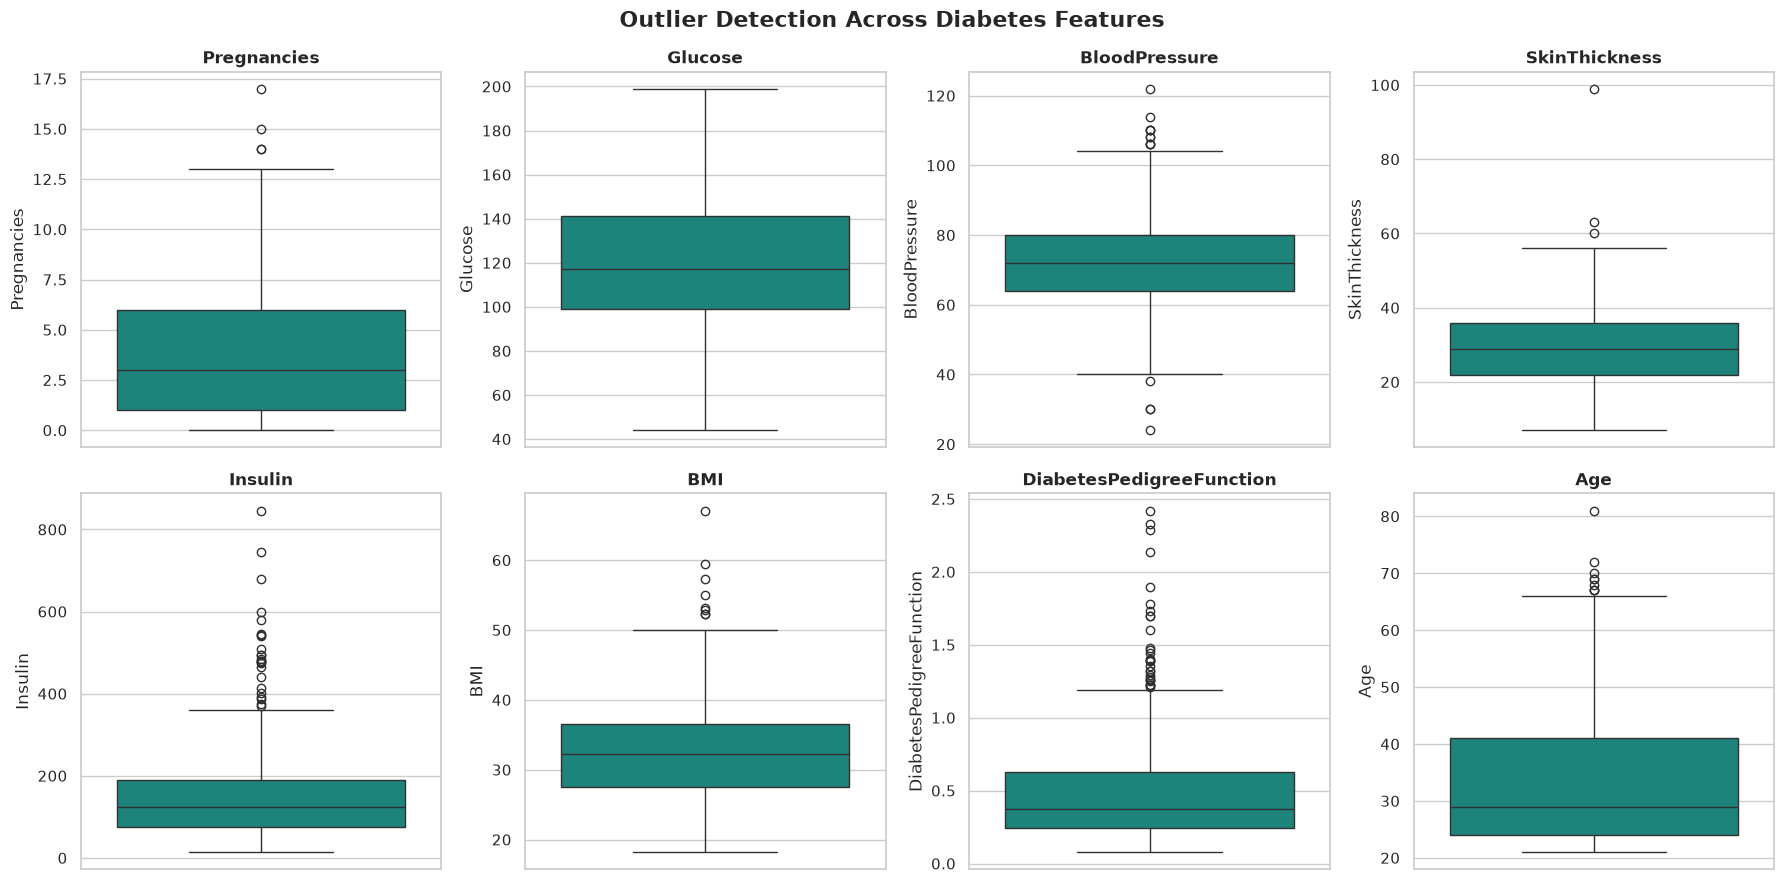

In [55]:

# Create a copy to keep the original dataset unchanged
outlier_df = df.copy()

# Replace invalid zero measurements with missing values
outlier_df[invalid_zero_columns] = outlier_df[invalid_zero_columns].replace(0, float("nan"))

# Create a grid of boxplots for all eight features
fig, axes = plt.subplots(2, 4, figsize=(18, 9))

# Plot each feature separately
for ax, feature in zip(axes.flat, features):
    sns.boxplot(
        y=outlier_df[feature],
        color="#0D9488",
        ax=ax
    )

    # Add a title and label to each boxplot
    ax.set_title(feature, fontsize=12, fontweight="bold")
    ax.set_ylabel(feature)

# Add the main title and adjust spacing
fig.suptitle("Outlier Detection Across Diabetes Features", fontsize=16, fontweight="bold")
plt.tight_layout()

# Display the boxplots
plt.show()


## Correlation Heatmap

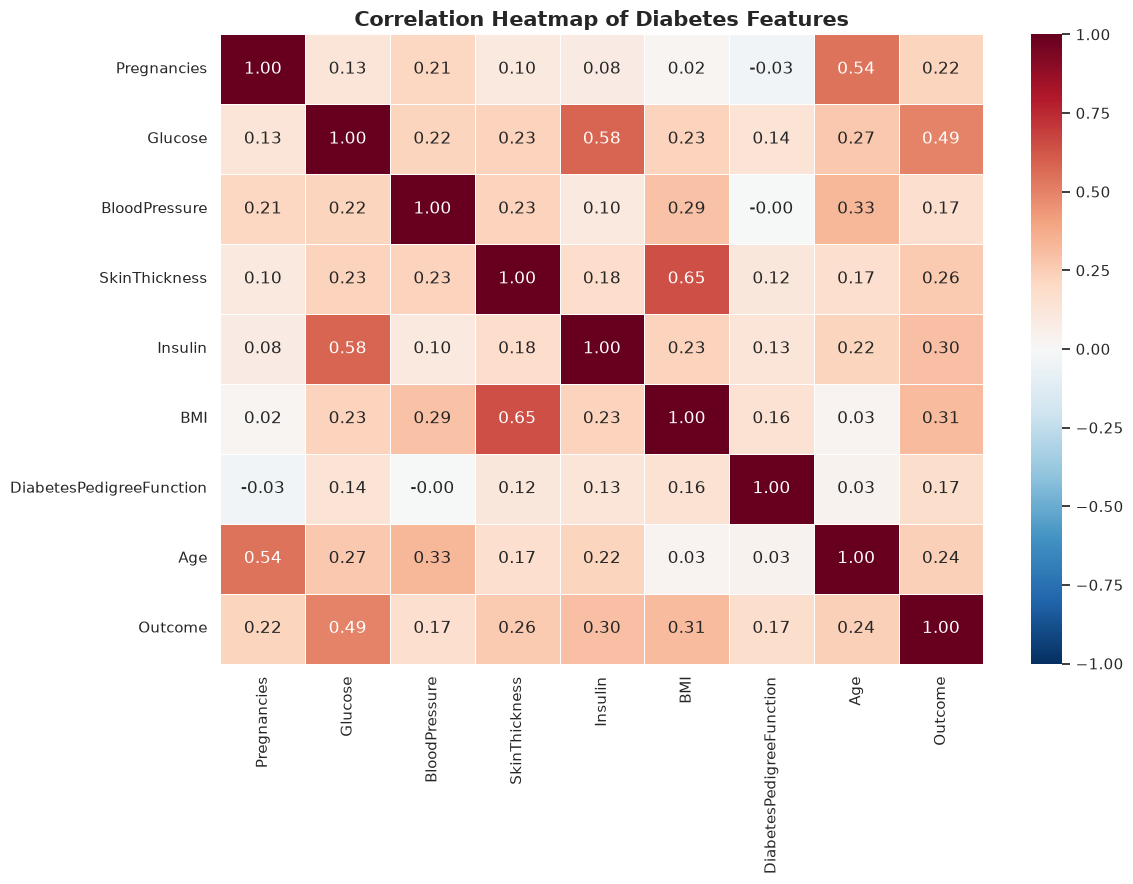

In [56]:

# Create a copy for correlation analysis
corr_df = df.copy()

# Replace invalid zeros with missing values
corr_df[invalid_zero_columns] = corr_df[invalid_zero_columns].replace(0, float("nan"))

# Calculate the correlation between numerical columns
correlation_matrix = corr_df.corr()

# Create the correlation heatmap
plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

# Add the chart title
plt.title("Correlation Heatmap of Diabetes Features", fontsize=15, fontweight="bold")

# Adjust spacing and display the chart
plt.tight_layout()
plt.show()
